# Final Data Project


<i>Susanna Carta</i>

For my story, I am using data about the <b>1522 helpline for gender-based violence and stalking during the pandemic in Italy</b> that can be <a href="https://www.istat.it/en/archivio/250811">here</a>, on the Italian National Institute of Statistics' (Istat) website. 
The main interesting finding is that calls to the helpline increased by about 71% during the lockdown period compared to the previous year, but I want to investigate this further.

In [290]:
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as px
import plotly.graph_objs as go
%matplotlib inline
pd.options.plotting.backend = "plotly"
#pip install plotly
#pip install plotly pandas
#!pip install chart_studio
%pip install --upgrade kaleido
%pip install --upgrade "plotly>=6.1.1"

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### Dataset #1: Valid and not valid calls (nuisance calls) to 1522 for reasons for the calls. Reference period March - October. Years 2013/2020, in absolute values.

This is the first dataset I want to use to show the overall increase in calls by reason in 2020 compared to previous years. First, I import the dataset and I rename the column headers.

In [291]:
allcalls = pd.read_excel('1522-dataset.xlsx')

In [292]:
allcalls.head(20)

,"Table 1 - Valid and not valid calls (nuisance calls) to 1522 for reasons for the calls. Reference period March - October. Years 2013/2020, in absolute values.",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
0,NaN,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0
1,Valid calls (users),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,victim of violence seeking for help,7064.0,4672.0,3487.0,3620.0,3288.0,4567.0,4329.0,8608.0
3,legal information,722.0,896.0,397.0,421.0,374.0,628.0,254.0,394.0
4,victim of stalking seeking for help,1463.0,873.0,685.0,672.0,569.0,610.0,592.0,934.0
5,useful phone numbers for out of target calls,4618.0,2425.0,1439.0,1025.0,1022.0,1883.0,1074.0,3493.0
6,reporting of violence,2083.0,1281.0,1030.0,1095.0,975.0,947.0,782.0,1969.0
7,information about national shelters for victim...,5068.0,5027.0,4396.0,3416.0,2806.0,2808.0,2016.0,3340.0
8,information about the helpline 1522,1476.0,1417.0,1263.0,1294.0,1445.0,3099.0,4108.0,4061.0
9,information for professionals on the procedure...,80.0,27.0,19.0,20.0,24.0,19.0,27.0,47.0


In [293]:
allcalls_renamedcolumns = allcalls.rename(columns={'Table 1 - Valid and not valid calls (nuisance calls) to 1522 for reasons for the calls. Reference period March - October. Years 2013/2020, in absolute values.': 'Calls', 'Unnamed: 1': '2013', 'Unnamed: 2': '2014', 'Unnamed: 3': '2015', 'Unnamed: 4': '2016', 'Unnamed: 5': '2017', 'Unnamed: 6': '2018', 'Unnamed: 7': '2019', 'Unnamed: 8': '2020'})

In [294]:
allcalls_renamedcolumns.head()

,Calls,2013,2014,2015,2016,2017,2018,2019,2020
0,NaN,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0
1,Valid calls (users),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,victim of violence seeking for help,7064.0,4672.0,3487.0,3620.0,3288.0,4567.0,4329.0,8608.0
3,legal information,722.0,896.0,397.0,421.0,374.0,628.0,254.0,394.0
4,victim of stalking seeking for help,1463.0,873.0,685.0,672.0,569.0,610.0,592.0,934.0


<b>Now I want to drop superfluous rows (0,1), rows that tell me about non valid calls (18,19), and the total for valid calls (17), so that it doesn't interfere with my visualisation.</b>

In [295]:
allcalls_droprows = allcalls_renamedcolumns.drop([0, 1,20])

In [296]:
allcalls_droprows

,Calls,2013,2014,2015,2016,2017,2018,2019,2020
2,victim of violence seeking for help,7064.0,4672.0,3487.0,3620.0,3288.0,4567.0,4329.0,8608.0
3,legal information,722.0,896.0,397.0,421.0,374.0,628.0,254.0,394.0
4,victim of stalking seeking for help,1463.0,873.0,685.0,672.0,569.0,610.0,592.0,934.0
5,useful phone numbers for out of target calls,4618.0,2425.0,1439.0,1025.0,1022.0,1883.0,1074.0,3493.0
6,reporting of violence,2083.0,1281.0,1030.0,1095.0,975.0,947.0,782.0,1969.0
7,information about national shelters for victim...,5068.0,5027.0,4396.0,3416.0,2806.0,2808.0,2016.0,3340.0
8,information about the helpline 1522,1476.0,1417.0,1263.0,1294.0,1445.0,3099.0,4108.0,4061.0
9,information for professionals on the procedure...,80.0,27.0,19.0,20.0,24.0,19.0,27.0,47.0
10,information on legal responsibility of the pub...,25.0,8.0,12.0,23.0,20.0,14.0,28.0,18.0
11,emergency,185.0,179.0,102.0,93.0,122.0,125.0,127.0,109.0


In [297]:
validcalls = allcalls_droprows.drop([17,18,19])

In [298]:
validcalls.head(20)

,Calls,2013,2014,2015,2016,2017,2018,2019,2020
2,victim of violence seeking for help,7064.0,4672.0,3487.0,3620.0,3288.0,4567.0,4329.0,8608.0
3,legal information,722.0,896.0,397.0,421.0,374.0,628.0,254.0,394.0
4,victim of stalking seeking for help,1463.0,873.0,685.0,672.0,569.0,610.0,592.0,934.0
5,useful phone numbers for out of target calls,4618.0,2425.0,1439.0,1025.0,1022.0,1883.0,1074.0,3493.0
6,reporting of violence,2083.0,1281.0,1030.0,1095.0,975.0,947.0,782.0,1969.0
7,information about national shelters for victim...,5068.0,5027.0,4396.0,3416.0,2806.0,2808.0,2016.0,3340.0
8,information about the helpline 1522,1476.0,1417.0,1263.0,1294.0,1445.0,3099.0,4108.0,4061.0
9,information for professionals on the procedure...,80.0,27.0,19.0,20.0,24.0,19.0,27.0,47.0
10,information on legal responsibility of the pub...,25.0,8.0,12.0,23.0,20.0,14.0,28.0,18.0
11,emergency,185.0,179.0,102.0,93.0,122.0,125.0,127.0,109.0


#### Replacing categories with 'other reasons'
I feel like I have too many reasons, and many of them show very low numbers. Therefore I want to group all categories that don't reach 1000 calls in 2020 into a 'other reasons' category by using <b>replace</b>. The only one I don't include is 'victim of stalking seeking for help' because it reaches 934 calls and is an interesting data as it refers to victims themselves.

In [299]:
validcalls_reduced = validcalls.replace({'legal information': 'other reasons', 'information for professionals on the procedures to be followed in the event of violence' : 'other reasons', 'information on legal responsibility of the public services workers' : 'other reasons', 'emergency': 'other reasons', 'reporting of public services malfunctions' : 'other reasons', 'international after hours calls' : 'other reasons', 'victim of discrimination seeking for help': 'other reasons', 'reporting of media misinformation' : 'other reasons', 'N.A.': 'other reasons'})

In [300]:
validcalls_reduced.head()

,Calls,2013,2014,2015,2016,2017,2018,2019,2020
2,victim of violence seeking for help,7064.0,4672.0,3487.0,3620.0,3288.0,4567.0,4329.0,8608.0
3,other reasons,722.0,896.0,397.0,421.0,374.0,628.0,254.0,394.0
4,victim of stalking seeking for help,1463.0,873.0,685.0,672.0,569.0,610.0,592.0,934.0
5,useful phone numbers for out of target calls,4618.0,2425.0,1439.0,1025.0,1022.0,1883.0,1074.0,3493.0
6,reporting of violence,2083.0,1281.0,1030.0,1095.0,975.0,947.0,782.0,1969.0


In [301]:
#I sum up all 'other reasons' categories into one row
validcalls_reducedsum = validcalls_reduced.groupby(['Calls']).sum()

In [302]:
validcalls_reducedsum

,2013,2014,2015,2016,2017,2018,2019,2020
Calls,,,,,,,,
information about national shelters for victims of violence,5068.0,5027.0,4396.0,3416.0,2806.0,2808.0,2016.0,3340.0
information about the helpline 1522,1476.0,1417.0,1263.0,1294.0,1445.0,3099.0,4108.0,4061.0
other reasons,1624.0,1229.0,598.0,610.0,667.0,860.0,523.0,666.0
reporting of violence,2083.0,1281.0,1030.0,1095.0,975.0,947.0,782.0,1969.0
useful phone numbers for out of target calls,4618.0,2425.0,1439.0,1025.0,1022.0,1883.0,1074.0,3493.0
victim of stalking seeking for help,1463.0,873.0,685.0,672.0,569.0,610.0,592.0,934.0
victim of violence seeking for help,7064.0,4672.0,3487.0,3620.0,3288.0,4567.0,4329.0,8608.0


In [303]:
#I reset the index because the above version doesn't work with plotly
validcalls_resetindex = validcalls_reducedsum.reset_index()

In [304]:
validcalls_resetindex

,Calls,2013,2014,2015,2016,2017,2018,2019,2020
0,information about national shelters for victim...,5068.0,5027.0,4396.0,3416.0,2806.0,2808.0,2016.0,3340.0
1,information about the helpline 1522,1476.0,1417.0,1263.0,1294.0,1445.0,3099.0,4108.0,4061.0
2,other reasons,1624.0,1229.0,598.0,610.0,667.0,860.0,523.0,666.0
3,reporting of violence,2083.0,1281.0,1030.0,1095.0,975.0,947.0,782.0,1969.0
4,useful phone numbers for out of target calls,4618.0,2425.0,1439.0,1025.0,1022.0,1883.0,1074.0,3493.0
5,victim of stalking seeking for help,1463.0,873.0,685.0,672.0,569.0,610.0,592.0,934.0
6,victim of violence seeking for help,7064.0,4672.0,3487.0,3620.0,3288.0,4567.0,4329.0,8608.0







<b> I want to look at the percentage change between 2019 and 2020, but I'm not going to use it for any visualisation.</b>

In [305]:
validcalls_percentage_change = validcalls_resetindex[['2019', '2020']].apply(lambda row: (row.iloc[0]-row.iloc[1])/row.iloc[0]*100, axis=1)

In [306]:
validcalls_percentage_change.round(1)

0    -65.7
1      1.1
2    -27.3
3   -151.8
4   -225.2
5    -57.8
6    -98.8
dtype: float64

### Creating the long version of my dataset

I want to make my dataframe 'long' using .melt because it works better with the plotly visualisation I want to make.

In [307]:
validcalls_long = validcalls_resetindex.melt(id_vars=['Calls'], 
                          value_vars=['2013','2014', '2015', '2016', '2017', '2018', '2019', '2020'],
                          value_name='value',
                          var_name = 'year')

In [308]:
validcalls_long.head()

,Calls,year,value
0,information about national shelters for victim...,2013,5068.0
1,information about the helpline 1522,2013,1476.0
2,other reasons,2013,1624.0
3,reporting of violence,2013,2083.0
4,useful phone numbers for out of target calls,2013,4618.0


<b>Now I rename column headers so that they look better in the visualisation I want to make</b>

In [309]:
validcalls_renamed = validcalls_long.rename(columns={'Calls': 'Reason for calling', 'value':'Number of calls', 'year':'Year'})

In [310]:
validcalls_renamed.head()

,Reason for calling,Year,Number of calls
0,information about national shelters for victim...,2013,5068.0
1,information about the helpline 1522,2013,1476.0
2,other reasons,2013,1624.0
3,reporting of violence,2013,2083.0
4,useful phone numbers for out of target calls,2013,4618.0


### Making a line chart

I use <b>plotly express</b> to make this visualisation. 

In [311]:
#I set the x and y axis and the column for the legend (color), and I order the categories in descending order
validcalls_linechart = px.line(validcalls_renamed, 
        x="Year", 
        y="Number of calls", 
       color='Reason for calling',
       title="Valid calls to 1522",
    width=1000, height=600,
       category_orders={"Reason for calling": ["victim of violence seeking for help", "information about the helpline 1522", "useful phone numbers for out of target calls", "information about national shelters for victims of violence", "reporting of violence", "victim of stalking seeking for help", 'other reasons']
                       
            }
)

In [312]:
validcalls_linechart.layout.template = 'plotly_white' #I pick one of the plotly templates

In [313]:
validcalls_linechart

In [314]:
validcalls_linechart.update_layout(
    font=dict(size=18),
    title_font=dict(size=26),
    width=1800,
    height=1000
)

In [315]:
validcalls_linechart.write_image(
    "validcalls_linechart.png",
    scale=3
)

In [316]:
validcalls_linechart.write_html(
    "my_visualisation.html",
    include_plotlyjs="cdn"
)

In [317]:
with open("my_visualisation.json", "w") as f:
    f.write(validcalls_linechart.to_json())

### Uploading my line chart to plotly chart studio

I want to get a link to embed my visualisation on a website, so I import plotly chart studio as py and I use the following code to generate a link:

## Dataset #2: Calls from users from 1st of March 2020 to 31th of October 2020. Years 2013-2020 in absolute values

I want to use this dataset as it gives me insight on how calls increase throughout 2020. Did they only increase during lockdown? In the previous chart, I saw that less people called to ask information about the helpline 1522, so it is possible that people were more informed in 2020, possibly because of institutional and NGO campaigns to raise awareness about the helpline. This could be very interesting for my story: did calls increase only due to the lockdown, or also because there was more awareness around the helpline?

This dataset includes non valid calls, but there was no way to extract valid calls from these numbers.

In [318]:
lockdownincrease = pd.read_excel("1522-dataset.xlsx",
             sheet_name='Table 7')

In [319]:
lockdownincrease.head()

,Table 7 - Calls from users from 1st of March 2020 to 31th of October 2020. Years 2013-2020 in absolute values,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
0,NaN,Chiamate valide,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,2013,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0
2,2020-03-01 00:00:00,75,58.0,30.0,41.0,45.0,60.0,66.0,34.0
3,2020-03-02 00:00:00,58,39.0,50.0,33.0,39.0,65.0,48.0,63.0
4,2020-03-03 00:00:00,54,80.0,52.0,62.0,50.0,54.0,49.0,52.0


In [320]:
lockdownincrease_droprows = lockdownincrease.drop([0,1,247]) #I drop rows that don't give me any information

In [321]:
lockdownincrease_droprows.head()

,Table 7 - Calls from users from 1st of March 2020 to 31th of October 2020. Years 2013-2020 in absolute values,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
2,2020-03-01 00:00:00,75,58.0,30.0,41.0,45.0,60.0,66.0,34.0
3,2020-03-02 00:00:00,58,39.0,50.0,33.0,39.0,65.0,48.0,63.0
4,2020-03-03 00:00:00,54,80.0,52.0,62.0,50.0,54.0,49.0,52.0
5,2020-03-04 00:00:00,113,89.0,42.0,57.0,34.0,54.0,57.0,38.0
6,2020-03-05 00:00:00,89,63.0,51.0,40.0,33.0,65.0,56.0,44.0


In [322]:
#I want to drop all columns except for 2020, as it is the only year I'm interested in
lockdownincrease_dropcolumns = lockdownincrease_droprows.drop(lockdownincrease_droprows.columns[1:8], axis=1)

In [323]:
lockdownincrease_dropcolumns

,Table 7 - Calls from users from 1st of March 2020 to 31th of October 2020. Years 2013-2020 in absolute values,Unnamed: 8
2,2020-03-01 00:00:00,34.0
3,2020-03-02 00:00:00,63.0
4,2020-03-03 00:00:00,52.0
5,2020-03-04 00:00:00,38.0
6,2020-03-05 00:00:00,44.0
...,...,...
242,2020-10-27 00:00:00,75.0
243,2020-10-28 00:00:00,64.0
244,2020-10-29 00:00:00,58.0
245,2020-10-30 00:00:00,57.0


In [324]:
#I rename the column headers for my visualisation
lockdownincrease_renamedcolumns = lockdownincrease_dropcolumns.rename(columns={'Table 7 - Calls from users from 1st of March 2020 to 31th of October 2020. Years 2013-2020 in absolute values': 'Date', 'Unnamed: 8': 'Number of calls' })

In [325]:
lockdownincrease_renamedcolumns.head()

,Date,Number of calls
2,2020-03-01 00:00:00,34.0
3,2020-03-02 00:00:00,63.0
4,2020-03-03 00:00:00,52.0
5,2020-03-04 00:00:00,38.0
6,2020-03-05 00:00:00,44.0


### Visualisation #2

I make another line chart with plotly express, because I have data from every day, it does not look very good. But I believe that is the best way to show change through time.

In [326]:
lockdownincrease_linechart = px.line(lockdownincrease_renamedcolumns, 
        x="Date", 
        y="Number of calls", 
       title="Valid and non valid calls to 1522 between March-October 2020",
    width=1000, height=600
                       
    
)

In [327]:
lockdownincrease_linechart.layout.template = 'plotly_white' #same template as visualisation #1 for consistency

### Add trace: time stamp line
I want to add a line marking the day the 1522 awareness campaign was <a href="https://www.1522.eu/libera-puoi-la-nuova-campagna-per-le-donne-vittime-di-violenza/">launched</a> by the Equal Opportunities Department of the Italian government. It seems that this date corresponds with a rise in calls. I am aware that calls started rising in the previous few days as well, but I still think it can be relevant.

The only way I managed to do this is by adding another trace, and I had to add a value to the y axis even though
it makes no sense. So I edited the 'hovertemplate' in order to only show the value of the x axis (24 March, the date I'm interested in). I also made the line dashed so that both traces were well visible.

In [328]:

lockdownincrease_linechart.add_trace(go.Scatter(x=['2020-03-24 00:00:00', '2020-03-24 00:00:00'], y=[0,230], 
                                                                             mode="lines", line={'dash': 'dash', 'width':1}, 
                                                                             name="Start of 1522 awareness campaign", 
                                                                             hovertemplate = '<br> %{x}<br>', showlegend = True))

<b>Just like for the previous visualisation, I upload my chart to plotly chart studio in order to get a link.</b>

In [376]:
# Increase all text sizes
lockdownincrease_linechart.update_layout(
    font_size=26,
    title=dict(
        text="Valid and non valid calls to 1522 between March-October 2020",
        font=dict(size=32)
    ),
    width=1800,
    height=1000
)

# Explicitly enlarge axis titles and tick labels
lockdownincrease_linechart.update_xaxes(
    title_font=dict(size=26),
    tickfont=dict(size=22)
)

lockdownincrease_linechart.update_yaxes(
    title_font=dict(size=26),
    tickfont=dict(size=22)
)

# Enlarge legend text
lockdownincrease_linechart.update_traces(
    selector=dict(name="Start of 1522 awareness campaign"),
    line=dict(width=2)
)

lockdownincrease_linechart.update_layout(
    legend=dict(font=dict(size=22))
)

# Export
lockdownincrease_linechart.write_image(
    "lockdownincrease_linechart.png",
    width=1800,
    height=1000,
    scale=3
)

## Dataset #3: Transfer of the call to another service and type of sending service. Reference period March - October. Years 2013-2020 in absolute values

This dataset tells me about the services where victims were redirected. These numbers only include calls by victims, rather than all users. I want to see whether less people were redirected to anti-violence centers, in order to get some insight into whether the pandemic affected the work of these centers. I'm aware that redirecting a call is not the same as actually granting a place in the centers, but if I find an interesting change between 2019 and 2020, it might mean that the work of centers was either strengthened or weakened due to lockdown restrictions.

In [329]:
antiviolencecentres = pd.read_excel("1522-dataset.xlsx",
             sheet_name='Table 20')

In [330]:
antiviolencecentres.head()

,Table 20 - Transfer of the call to another service and type of sending service. Reference period March - October. Years 2013-2020 in absolute values,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
0,NaN,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0
1,Transfer to other service,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Yes,9736.0,6261.0,4848.0,5012.0,4465.0,5274.0,4877.0,8831.0
3,No,1065.0,727.0,453.0,463.0,485.0,973.0,950.0,2787.0
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [331]:
#I rename columns I'm interested in
antiviolencecentres_renamedcolumns = antiviolencecentres.rename(columns={'Table 20 - Transfer of the call to another service and type of sending service. Reference period March - October. Years 2013-2020 in absolute values': 'Transfer to other service','Unnamed: 7': '2019', 'Unnamed: 8': '2020'})

In [332]:
antiviolencecentres_renamedcolumns.head()

,Transfer to other service,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,2019,2020
0,NaN,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0
1,Transfer to other service,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Yes,9736.0,6261.0,4848.0,5012.0,4465.0,5274.0,4877.0,8831.0
3,No,1065.0,727.0,453.0,463.0,485.0,973.0,950.0,2787.0
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [333]:
#I drop years from 2013 to 2018, as I only want to look at the most recent years
antiviolencecentres_dropcolumns = antiviolencecentres_renamedcolumns.drop(antiviolencecentres_renamedcolumns.columns[1:7], axis=1)

In [334]:
antiviolencecentres_dropcolumns.head()

,Transfer to other service,2019,2020
0,NaN,2019.0,2020.0
1,Transfer to other service,NaN,NaN
2,Yes,4877.0,8831.0
3,No,950.0,2787.0
4,NaN,NaN,NaN


In [335]:
#I drop all NaN values
antiviolencecentres_dropna = antiviolencecentres_dropcolumns.dropna(axis=0)

In [336]:
antiviolencecentres_dropna.head(24)

,Transfer to other service,2019,2020
2,Yes,4877.0,8831.0
3,No,950.0,2787.0
6,112 - Police Stations,96.0,192.0
7,113 - PS Commissariats,5.0,47.0
8,Caritas ONG,6.0,13.0
9,Protected and welcoming houses,13.0,183.0
10,Centres with only antistalking services,0.0,7.0
11,Anti-violence Centers and Services,4241.0,7741.0
12,Job Centres,1.0,3.0
13,Equality Councillor,7.0,10.0


<b>I want to group different services into one 'Other services' category just like I did in the first dataset. This time I found a way to only repeat 'Other services' once.</b>

In [337]:


antiviolencecentres_replace = antiviolencecentres_dropna.replace(to_replace={'112 - Police Stations',
'113 - PS Commissariats', 'Caritas ONG', 'Protected and welcoming houses', 'Centres with only antistalking services', 'Job Centres', 
 'Equality Councillor', 
'Family Consultancy',
'Mental Health Department',
'Anti-Trafficking Number',
'First aid',
'Dedicated first aid',
'Social Services',
'Police headquarters',
'Public health psychology services',
'Emergency health service 118', 'National Helpline for discrimination (UNAR)',
'N.A.'}, value="Other services", regex=True)

In [338]:
antiviolencecentres_replace

,Transfer to other service,2019,2020
2,Yes,4877.0,8831.0
3,No,950.0,2787.0
6,Other services,96.0,192.0
7,Other services,5.0,47.0
8,Other services,6.0,13.0
9,Other services,13.0,183.0
10,Other services,0.0,7.0
11,Anti-violence Centers and Services,4241.0,7741.0
12,Other services,1.0,3.0
13,Other services,7.0,10.0


In [339]:
#For some reason the previous code didn't work for row 23. I drop it again.
antiviolencecentres_replace2 = antiviolencecentres_replace.replace({'National Helpline for discrimination (UNAR)': 'Other services'})

In [340]:
antiviolencecentres_replace2

,Transfer to other service,2019,2020
2,Yes,4877.0,8831.0
3,No,950.0,2787.0
6,Other services,96.0,192.0
7,Other services,5.0,47.0
8,Other services,6.0,13.0
9,Other services,13.0,183.0
10,Other services,0.0,7.0
11,Anti-violence Centers and Services,4241.0,7741.0
12,Other services,1.0,3.0
13,Other services,7.0,10.0


In [341]:
#I sum up all the 'Other' rows
antiviolencecentres_reduced = antiviolencecentres_replace2.groupby(['Transfer to other service']).sum()

In [342]:
antiviolencecentres_reduced


,2019,2020
Transfer to other service,,
Anti-violence Centers and Services,4241.0,7741.0
No,950.0,2787.0
Other services,636.0,1090.0
Yes,4877.0,8831.0


In [343]:
#I reset the index to help me out later with my visualisation
antiviolencecentres_resetind = antiviolencecentres_reduced.reset_index()

In [344]:
antiviolencecentres_resetind

,Transfer to other service,2019,2020
0,Anti-violence Centers and Services,4241.0,7741.0
1,No,950.0,2787.0
2,Other services,636.0,1090.0
3,Yes,4877.0,8831.0


<b>I debated how to show this in an understandable and transparent way, and I decided to drop the Yes row as it is the total of 'Other services' and 'Anti-violence centers and services'.</b>

In [345]:
antiviolencecentres_dropyes = antiviolencecentres_resetind.drop([3])

In [346]:
antiviolencecentres_dropyes

,Transfer to other service,2019,2020
0,Anti-violence Centers and Services,4241.0,7741.0
1,No,950.0,2787.0
2,Other services,636.0,1090.0


In [347]:
#Since I dropped the 'Yes' category, I want to clarify what No means.
antiviolencecentres_notransfer = antiviolencecentres_dropyes.replace({'No': 'No transfer'})

In [348]:
antiviolencecentres_notransfer

,Transfer to other service,2019,2020
0,Anti-violence Centers and Services,4241.0,7741.0
1,No transfer,950.0,2787.0
2,Other services,636.0,1090.0


I don't want to compare absolute values for this visualisation, but proportions for each year. I had some troubles to create a new dataframe and avoid changing the values of the previous one, but it didn't work in any way. It is possible that by running this notebook, 'antiviolencecentres_notransfer' will show percentages even before I run the following codes.

In [349]:
antiviolencecentres_notransfer['2019'] = (antiviolencecentres_notransfer['2019'] / 
                      antiviolencecentres_notransfer['2019'].sum()) * 100

In [350]:
antiviolencecentres_notransfer['2020'] = (antiviolencecentres_notransfer['2020'] / 
                      antiviolencecentres_notransfer['2020'].sum()) * 100

In [351]:
#I want to round percentages to 1 decimal
antiviolencecentres_rounded = antiviolencecentres_notransfer.round(1)

In [352]:
#I make this dataframe 'long' for it to work best on plotly express
antiviolencecentres_long = antiviolencecentres_rounded.melt(id_vars=['Transfer to other service'], 
                          value_vars=['2019', '2020'],
                          value_name='Percentage',
                          var_name = 'Year')

In [353]:
antiviolencecentres_long

,Transfer to other service,Year,Percentage
0,Anti-violence Centers and Services,2019,72.8
1,No transfer,2019,16.3
2,Other services,2019,10.9
3,Anti-violence Centers and Services,2020,66.6
4,No transfer,2020,24.0
5,Other services,2020,9.4


### Visualisation #3: bar chart

I thought about making a grouped bar chart but I decided to stack it so that it is clear that the total for each year is 100% and I'm comparing proportions for each year

In [354]:
antiviolencecentres_barchart = px.bar(antiviolencecentres_long, x="Year", 
             y='Percentage', color='Transfer to other service',
             title="Transfer of the call to other services in %",
             barmode='stack',
             height=600
            )
antiviolencecentres_barchart.layout.template = 'plotly_white' #usual template

antiviolencecentres_barchart.show()

In [355]:
#I want to add the % symbol as a suffix to all numbers, I tried to do it before making the chart but it made
#the values of the y axis incomprehensible, so I'm doing it this way.
antiviolencecentres_barchart.update_layout(
    yaxis = dict(ticksuffix= "%"))


# Dataset #4: Place of the violent act reported by victims. Reference period March - October. Years 2013-2020 in absolute values

My last question is: did the lockdown make domestic violence incidents rise compared to other types of violence? So I'm looking at the places where the violence occurred. This data comes from information given by victims, who often prefer not to respond, so there are many instances of Other and No response. I want to keep them in the visualisation, but I'm going to group them into a 'Non available' category. For this visualisation, I only want to look at 2019 and 2020, just to see the most recent impact of the lockdown.

In [356]:
location = pd.read_excel("1522-dataset.xlsx",
             sheet_name='Table 15')

In [357]:
location.head(10)

,Table 15 - Place of the violent act reported by victims. Reference period March - October. Years 2013-2020 in absolute values,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
0,Place of the violent act,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Your home,7319.0,5019.0,4012.0,4069.0,3673.0,4731.0,4354.0,8608.0
3,The workplace,173.0,109.0,95.0,106.0,84.0,131.0,114.0,202.0
4,The road,245.0,158.0,82.0,120.0,96.0,105.0,84.0,174.0
5,Other people's home,187.0,93.0,37.0,64.0,61.0,88.0,57.0,102.0
6,A public place,65.0,39.0,15.0,31.0,36.0,33.0,26.0,60.0
7,The car,27.0,38.0,10.0,21.0,14.0,17.0,18.0,28.0
8,Other,113.0,90.0,44.0,99.0,84.0,103.0,202.0,439.0
9,No response,0.0,58.0,31.0,33.0,32.0,52.0,18.0,446.0


In [358]:
#Usual rename of column headers
location_renamed = location.rename(columns={'Table 15 - Place of the violent act reported by victims. Reference period March - October. Years 2013-2020 in absolute values': 'Place of the violent act', 'Unnamed: 1': '2013', 'Unnamed: 2': '2014', 'Unnamed: 3': '2015', 'Unnamed: 4': '2016', 'Unnamed: 5': '2017', 'Unnamed: 6': '2018', 'Unnamed: 7': '2019', 'Unnamed: 8': '2020'})

In [359]:
location_renamed

,Place of the violent act,2013,2014,2015,2016,2017,2018,2019,2020
0,Place of the violent act,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Your home,7319.0,5019.0,4012.0,4069.0,3673.0,4731.0,4354.0,8608.0
3,The workplace,173.0,109.0,95.0,106.0,84.0,131.0,114.0,202.0
4,The road,245.0,158.0,82.0,120.0,96.0,105.0,84.0,174.0
5,Other people's home,187.0,93.0,37.0,64.0,61.0,88.0,57.0,102.0
6,A public place,65.0,39.0,15.0,31.0,36.0,33.0,26.0,60.0
7,The car,27.0,38.0,10.0,21.0,14.0,17.0,18.0,28.0
8,Other,113.0,90.0,44.0,99.0,84.0,103.0,202.0,439.0
9,No response,0.0,58.0,31.0,33.0,32.0,52.0,18.0,446.0


In [360]:
#I drop the first two rows that don't give me any information I don't already have
location_droprows = location_renamed.drop(location_renamed.index[:2])

In [361]:
location_droprows

,Place of the violent act,2013,2014,2015,2016,2017,2018,2019,2020
2,Your home,7319.0,5019.0,4012.0,4069.0,3673.0,4731.0,4354.0,8608.0
3,The workplace,173.0,109.0,95.0,106.0,84.0,131.0,114.0,202.0
4,The road,245.0,158.0,82.0,120.0,96.0,105.0,84.0,174.0
5,Other people's home,187.0,93.0,37.0,64.0,61.0,88.0,57.0,102.0
6,A public place,65.0,39.0,15.0,31.0,36.0,33.0,26.0,60.0
7,The car,27.0,38.0,10.0,21.0,14.0,17.0,18.0,28.0
8,Other,113.0,90.0,44.0,99.0,84.0,103.0,202.0,439.0
9,No response,0.0,58.0,31.0,33.0,32.0,52.0,18.0,446.0
10,N.A.,2672.0,1384.0,975.0,932.0,870.0,987.0,954.0,1559.0
11,Sources: Equal Opportunity Department - Presid...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [362]:
#I drop the last row which shows the source
location_dropsource = location_droprows.drop(location_droprows.index[9])

In [363]:
location_dropsource

,Place of the violent act,2013,2014,2015,2016,2017,2018,2019,2020
2,Your home,7319.0,5019.0,4012.0,4069.0,3673.0,4731.0,4354.0,8608.0
3,The workplace,173.0,109.0,95.0,106.0,84.0,131.0,114.0,202.0
4,The road,245.0,158.0,82.0,120.0,96.0,105.0,84.0,174.0
5,Other people's home,187.0,93.0,37.0,64.0,61.0,88.0,57.0,102.0
6,A public place,65.0,39.0,15.0,31.0,36.0,33.0,26.0,60.0
7,The car,27.0,38.0,10.0,21.0,14.0,17.0,18.0,28.0
8,Other,113.0,90.0,44.0,99.0,84.0,103.0,202.0,439.0
9,No response,0.0,58.0,31.0,33.0,32.0,52.0,18.0,446.0
10,N.A.,2672.0,1384.0,975.0,932.0,870.0,987.0,954.0,1559.0


In [364]:
#I drop all the years I'm not interested in
location_dropcolumns = location_dropsource.drop(location_dropsource.columns[1:7], axis=1)

In [365]:
location_dropcolumns

,Place of the violent act,2019,2020
2,Your home,4354.0,8608.0
3,The workplace,114.0,202.0
4,The road,84.0,174.0
5,Other people's home,57.0,102.0
6,A public place,26.0,60.0
7,The car,18.0,28.0
8,Other,202.0,439.0
9,No response,18.0,446.0
10,N.A.,954.0,1559.0


In [366]:
#I change the last two rows into 'Not available' and I rename 'your home' as 'home'
location_reduced = location_dropcolumns.replace({'No response': 'Not available','N.A.': 'Not available', 'Your home': 'Home'})

In [367]:
location_reduced

,Place of the violent act,2019,2020
2,Home,4354.0,8608.0
3,The workplace,114.0,202.0
4,The road,84.0,174.0
5,Other people's home,57.0,102.0
6,A public place,26.0,60.0
7,The car,18.0,28.0
8,Other,202.0,439.0
9,Not available,18.0,446.0
10,Not available,954.0,1559.0


In [368]:
#I sort values in descending order so that the visualisation legend will also show them this way
location_reduced.sort_values(by=['2019','2020'], ascending=False)

,Place of the violent act,2019,2020
2,Home,4354.0,8608.0
10,Not available,954.0,1559.0
8,Other,202.0,439.0
3,The workplace,114.0,202.0
4,The road,84.0,174.0
5,Other people's home,57.0,102.0
6,A public place,26.0,60.0
9,Not available,18.0,446.0
7,The car,18.0,28.0


## Visualisation #4: pie charts

I want to compare two pie charts for 2020 and 2019. First, I plot them individually with plotly express.

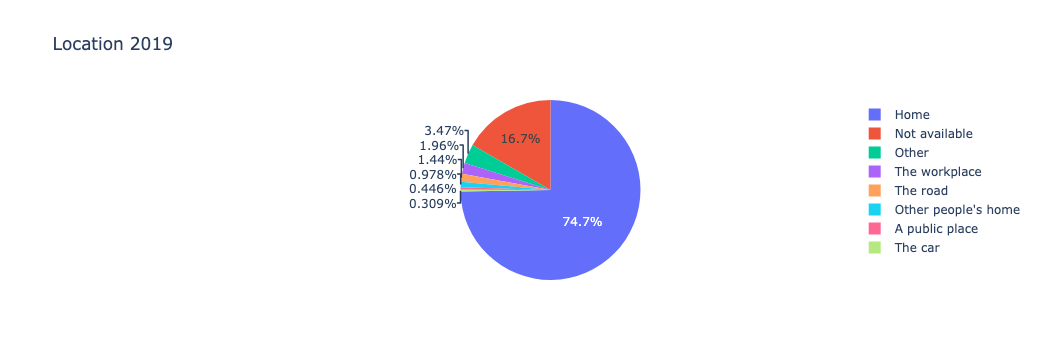

In [369]:
location_piechart2019 = px.pie(location_reduced, values='2019', names='Place of the violent act', title='Location 2019')
location_piechart2019.show()

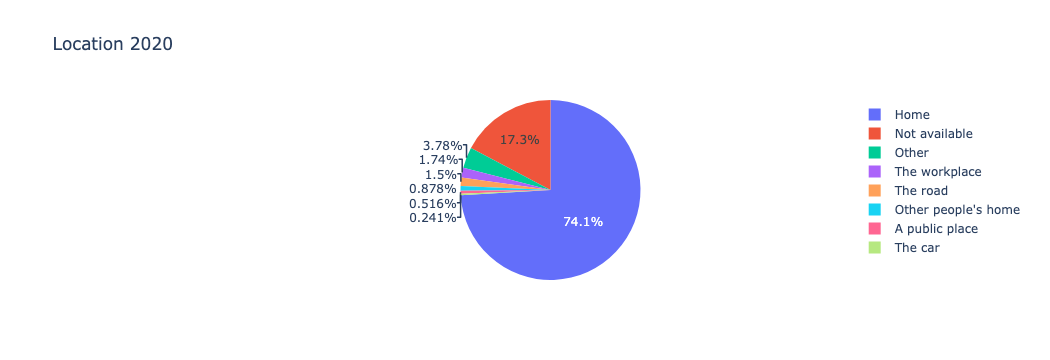

In [370]:
location_piechart2020 = px.pie(location_reduced, values='2020', names='Place of the violent act', title='Location 2020')
location_piechart2020.show()

I want to display the two charts side by side, so I use plotly.graph_objs and I plot the two pie charts as two traces and then I use 'domain' to be able to control the size and distance between the two. 

There are two drawbacks to this visualisation: firstly, I can only see which year each pie chart is referring to by hovering over them, and secondly, I'm not able to show the absolute values as the previous figures (location_piechart) did. But I could not find a way to plot the exact same figures as above side by side.

In [371]:
trace1 = go.Pie(
     values=location_reduced['2019'],
     labels=location_reduced['Place of the violent act'
             ],
     domain=dict(x=[0, 0.5], y=[0.5, 1]),
     name="2019",
     hoverinfo="label+percent+name",
)
trace2 = go.Pie(
     values=location_reduced['2020'],
     labels=location_reduced['Place of the violent act'],
   
     domain=dict(x=[0.5, 1.0], y=[0.5, 1]),
     name="2020",
     hoverinfo="label+percent+name",
)
layout = go.Layout(title="Places where violent acts occurred for 2019 and 2020")
data = [trace1, trace2]
location_sidebyside = go.Figure(data=data, layout=layout)

In [372]:
location_sidebyside.show()

In [380]:
location_sidebyside.update_traces(
    textinfo="percent",
    textfont=dict(size=20),
    insidetextorientation="auto"
)

location_sidebyside.update_layout(
    title_font_size=30,
    font=dict(size=22),
    legend=dict(font=dict(size=20)),
    width=1800,
    height=750,
    margin=dict(
        l=50,
        r=50,
        t=100,
        b=30
    )
)

location_sidebyside.write_image(
    "location_sidebyside.png",
    width=1800,
    height=750,
    scale=3
)

In [373]:
antiviolencecentres_barchart.update_traces(
    width=0.4
)

antiviolencecentres_barchart.update_layout(
    font=dict(size=18),
    title_font=dict(size=26),
    width=1800,
    height=1000
)

antiviolencecentres_barchart.write_image(
    "antiviolencecentres_barchart.png",
    width=1800,
    height=1000,
    scale=3
)

In [375]:
    font=dict(size=20),
    title_font=dict(size=28),
    xaxis=dict(
        title_font=dict(size=28),
        tickfont=dict(size=18)
    ),
    yaxis=dict(
        title_font=dict(size=28),
        tickfont=dict(size=18)
    ),
    legend=dict(font=dict(size=25),
    width=1800,
    height=1000
)

lockdownincrease_linechart.write_image(
    "lockdownincrease_linechart.png",
    width=1800,
    height=1000,
    scale=3
)

# End